# TCGA-KIRC: clinical baseline Cox model

## Purpose

This notebook establishes a clinical-only survival model using:

- Age at index
- Sex at birth
- Pathological stage
- Tumor grade

This is the baseline model that gene-expression variables would improve upon later.

## Dataset

`data/processed/tcga_kirc_clinical_survival_analysis.csv`


In [2]:
# 01-c1 Loads the clinical survival-analysis cohort

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from lifelines import CoxPHFitter

PROJECT_DIR = Path.cwd().parent

processed_clinical_file = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "tcga_kirc_clinical_survival_analysis.csv"
)

clinical_data = pd.read_csv(processed_clinical_file)

print("Number of patients:", len(clinical_data))
print("Number of deaths:", clinical_data["event_observed"].sum())
print("Number censored:", (clinical_data["event_observed"] == 0).sum())


'''Note: "Censored" means the patient was alive at their last recorded 
follow-up. As it is known they survived at least that long, but we have 
no information about their eventual death time. Survival analysis uses 
that known follow-up time correctly; it does not treat censored patients
as deaths or discard them'''

display(clinical_data.head())

Number of patients: 522
Number of deaths: 173
Number censored: 349


,patient_id,sex_at_birth,vital_status,age_at_index,days_to_death,primary_diagnosis,tumor_stage,tumor_grade,days_to_last_follow_up,maximum_days_to_follow_up,event_observed,overall_survival_days,overall_survival_years
0,TCGA-B0-5098,female,Dead,53,1584.0,"Clear cell adenocarcinoma, NOS",Stage I,G3,NaN,1584.0,1,1584.0,4.336756
1,TCGA-BP-4165,female,Alive,64,NaN,"Clear cell adenocarcinoma, NOS",Stage I,G1,NaN,3037.0,0,3037.0,8.314853
2,TCGA-BP-4166,male,Alive,69,NaN,"Clear cell adenocarcinoma, NOS",Stage III,G3,13.0,13.0,0,13.0,0.035592
3,TCGA-B0-4810,male,Dead,47,478.0,"Clear cell adenocarcinoma, NOS",Stage III,G3,NaN,478.0,1,478.0,1.308693
4,TCGA-DV-5568,male,Alive,26,NaN,"Clear cell adenocarcinoma, NOS",Stage I,G2,NaN,370.0,0,370.0,1.013005


### Check patient and death counts by clinical group

**Purpose:** Count patients and observed deaths by stage, grade, and sex before
fitting the Cox model.

In [3]:
# 02-c2 Checks patient and death counts by clinical group

def summarize_clinical_group(data, group_column, category_order):
    """Return patient counts and observed deaths for one clinical variable."""
    summary = (
        data.groupby(group_column, observed=True)
        .agg(
            patients=("patient_id", "count"),
            deaths=("event_observed", "sum"),
        )
        .reindex(category_order)
    )

    summary["death_percent"] = (
        100 * summary["deaths"] / summary["patients"]
    ).round(1)

    return summary


stage_order = ["Stage I", "Stage II", "Stage III", "Stage IV"]
grade_order = ["G1", "G2", "G3", "G4"]
sex_order = ["female", "male"]

print("By pathological stage:")
display(summarize_clinical_group(clinical_data, "tumor_stage", stage_order))

print("\nBy tumor grade:")
display(summarize_clinical_group(clinical_data, "tumor_grade", grade_order))

print("\nBy sex at birth:")
display(summarize_clinical_group(clinical_data, "sex_at_birth", sex_order))

By pathological stage:


,patients,deaths,death_percent
tumor_stage,,,
Stage I,261,43,16.5
Stage II,54,13,24.1
Stage III,124,50,40.3
Stage IV,83,67,80.7



By tumor grade:


,patients,deaths,death_percent
tumor_grade,,,
G1,13,0,0.0
G2,227,44,19.4
G3,206,74,35.9
G4,76,55,72.4



By sex at birth:


,patients,deaths,death_percent
sex_at_birth,,,
female,184,63,34.2
male,338,110,32.5


### Prepare predictors for the clinical Cox model

**Ref. groups:** female, Stage I, and G1.

**Age:** modelling per 10-year increase for ease of interpretation.

In [4]:
# 01-c3 Prepares predictors for the clinical Cox model

stage_order = ["Stage I", "Stage II", "Stage III", "Stage IV"]
grade_order = ["G1", "G2", "G3", "G4"]

cox_data = clinical_data[
    [
        "overall_survival_days",
        "event_observed",
        "age_at_index",
        "sex_at_birth",
        "tumor_stage",
        "tumor_grade",
    ]
].copy()

cox_data["age_per_10_years"] = cox_data["age_at_index"] / 10
cox_data["male"] = (cox_data["sex_at_birth"] == "male").astype(int)

cox_data["tumor_stage"] = pd.Categorical(
    cox_data["tumor_stage"],
    categories=stage_order,
)

cox_data["tumor_grade"] = pd.Categorical(
    cox_data["tumor_grade"],
    categories=grade_order,
)

cox_data = pd.get_dummies(
    cox_data,
    columns=["tumor_stage", "tumor_grade"],
    drop_first=True,
    dtype=int,
)

cox_data = cox_data.drop(columns=["age_at_index", "sex_at_birth"])

print("Model columns:")
print(list(cox_data.columns))

display(cox_data.head())

Model columns:
['overall_survival_days', 'event_observed', 'age_per_10_years', 'male', 'tumor_stage_Stage II', 'tumor_stage_Stage III', 'tumor_stage_Stage IV', 'tumor_grade_G2', 'tumor_grade_G3', 'tumor_grade_G4']


,overall_survival_days,event_observed,age_per_10_years,male,tumor_stage_Stage II,tumor_stage_Stage III,tumor_stage_Stage IV,tumor_grade_G2,tumor_grade_G3,tumor_grade_G4
0,1584.0,1,5.3,0,0,0,0,0,1,0
1,3037.0,0,6.4,0,0,0,0,0,0,0
2,13.0,0,6.9,1,0,1,0,0,1,0
3,478.0,1,4.7,1,0,1,0,0,1,0
4,370.0,0,2.6,1,0,0,0,1,0,0


### Fit the clinical-only Cox proportional-hazards model

**Purpose:** Estimate adjusted associations between clinical variables and overall survival.

**Interpretation:** A hazard ratio above 1 indicates higher estimated death hazard
than the reference group, after adjustment for the other listed variables.

In [5]:
# 02-c4 Fits the clinical-only Cox model

# Confirms no missing values entered the model.
assert cox_data.isna().sum().sum() == 0

clinical_cox_model = CoxPHFitter()

clinical_cox_model.fit(
    cox_data,
    duration_col="overall_survival_days",
    event_col="event_observed",
)

clinical_cox_results = (
    clinical_cox_model.summary[
        [
            "exp(coef)",
            "exp(coef) lower 95%",
            "exp(coef) upper 95%",
            "p",
        ]
    ]
    .rename(
        columns={
            "exp(coef)": "hazard_ratio",
            "exp(coef) lower 95%": "lower_95_CI",
            "exp(coef) upper 95%": "upper_95_CI",
            "p": "p_value",
        }
    )
    .round(3)
)

print(
    "Concordance index:",
    round(clinical_cox_model.concordance_index_, 3),
)

display(clinical_cox_results)

Concordance index: 0.769


/opt/anaconda3/envs/cancer-genomics-tcga-kirc/lib/python3.11/site-packages/lifelines/fitters/coxph_fitter.py:1607: ConvergenceWarning: Newton-Raphson convergence completed successfully but norm(delta) is still high, 0.781. This may imply non-unique solutions to the maximum likelihood. Perhaps there is collinearity or complete separation in the dataset?

  warnings.warn(


,hazard_ratio,lower_95_CI,upper_95_CI,p_value
covariate,,,,
age_per_10_years,1.354000e+00,1.170,1.568,0.000
male,9.410000e-01,0.685,1.292,0.705
tumor_stage_Stage II,1.216000e+00,0.649,2.278,0.541
tumor_stage_Stage III,2.084000e+00,1.361,3.189,0.001
tumor_stage_Stage IV,4.800000e+00,3.096,7.441,0.000
tumor_grade_G2,5.837185e+06,0.000,inf,0.994
tumor_grade_G3,8.400759e+06,0.000,inf,0.994
tumor_grade_G4,1.273440e+07,0.000,inf,0.994


### Diagnosing the Cox-model convergence warning

**Purpose:** Check whether one or more grade categories have too few observed deaths
to estimate a stable Cox-model effect.

In [6]:
# 02-c5 Diagnosing the Cox-model convergence warning

grade_event_summary = (
    clinical_data.groupby("tumor_grade", observed=True)
    .agg(
        patients=("patient_id", "count"),
        deaths=("event_observed", "sum"),
    )
    .reindex(["G1", "G2", "G3", "G4"])
)

grade_event_summary["death_percent"] = (
    100 * grade_event_summary["deaths"] / grade_event_summary["patients"]
).round(1)

display(grade_event_summary)

,patients,deaths,death_percent
tumor_grade,,,
G1,13,0,0.0
G2,227,44,19.4
G3,206,74,35.9
G4,76,55,72.4


Result confirmed: G1 has 13 patients and zero deaths. That causes the unstable grade estimates.
Threfore I shall use a clinically interpretable, stable grouping:
- low_grade: G1 or G2
- high_grade: G3 or G4
Grouping reorganized because G1 had zero observed deaths.

### Create a stable tumor-grade grouping

**Purpose:** Combine sparse G1 cases with G2 to avoid complete separation.

**Grade groups:**

- Low grade: G1 or G2
- High grade: G3 or G4

In [8]:
# 02-c6 Creates a stable tumor-grade grouping

clinical_data["grade_group"] = np.where(
    clinical_data["tumor_grade"].isin(["G1", "G2"]),
    "low_grade",
    "high_grade",
)

grade_group_summary = (
    clinical_data.groupby("grade_group", observed=True)
    .agg(
        patients=("patient_id", "count"),
        deaths=("event_observed", "sum"),
    )
    .reindex(["low_grade", "high_grade"])
)

grade_group_summary["death_percent"] = (
    100 * grade_group_summary["deaths"] / grade_group_summary["patients"]
).round(1)

display(grade_group_summary)

,patients,deaths,death_percent
grade_group,,,
low_grade,240,44,18.3
high_grade,282,129,45.7


### Fit the stable clinical-only Cox model

**Purpose:** Fit the primary clinical baseline model using age, sex, stage, and low-grade versus high-grade tumour classification.

**Ref. groups:** female, Stage I, and low grade.

In [9]:
# 02-07 Fits the stable clinical-only Cox model

stage_order = ["Stage I", "Stage II", "Stage III", "Stage IV"]

stable_cox_data = clinical_data[
    [
        "overall_survival_days",
        "event_observed",
        "age_at_index",
        "sex_at_birth",
        "tumor_stage",
        "grade_group",
    ]
].copy()

stable_cox_data["age_per_10_years"] = (
    stable_cox_data["age_at_index"] / 10
)

stable_cox_data["male"] = (
    stable_cox_data["sex_at_birth"] == "male"
).astype(int)

stable_cox_data["high_grade"] = (
    stable_cox_data["grade_group"] == "high_grade"
).astype(int)

stable_cox_data["tumor_stage"] = pd.Categorical(
    stable_cox_data["tumor_stage"],
    categories=stage_order,
)

stable_cox_data = pd.get_dummies(
    stable_cox_data,
    columns=["tumor_stage"],
    drop_first=True,
    dtype=int,
)

stable_cox_data = stable_cox_data.drop(
    columns=["age_at_index", "sex_at_birth", "grade_group"]
)

assert stable_cox_data.isna().sum().sum() == 0

stable_clinical_cox_model = CoxPHFitter()

stable_clinical_cox_model.fit(
    stable_cox_data,
    duration_col="overall_survival_days",
    event_col="event_observed",
)

stable_clinical_results = (
    stable_clinical_cox_model.summary[
        [
            "exp(coef)",
            "exp(coef) lower 95%",
            "exp(coef) upper 95%",
            "p",
        ]
    ]
    .rename(
        columns={
            "exp(coef)": "hazard_ratio",
            "exp(coef) lower 95%": "lower_95_CI",
            "exp(coef) upper 95%": "upper_95_CI",
            "p": "p_value",
        }
    )
    .round(3)
)

print(
    "Concordance index:",
    round(stable_clinical_cox_model.concordance_index_, 3),
)

display(stable_clinical_results)

Concordance index: 0.764


,hazard_ratio,lower_95_CI,upper_95_CI,p_value
covariate,,,,
age_per_10_years,1.354,1.171,1.565,0.000
male,0.953,0.694,1.310,0.767
high_grade,1.649,1.143,2.381,0.008
tumor_stage_Stage II,1.241,0.662,2.325,0.500
tumor_stage_Stage III,2.222,1.456,3.391,0.000
tumor_stage_Stage IV,5.683,3.766,8.578,0.000


Interpretation:
- Each 10-year age increase: HR 1.354.
- High grade (G3/G4) vs low grade (G1/G2): HR 1.649.
- Stage III vs Stage I: HR 2.222.
- Stage IV vs Stage I: HR 5.683.
- Sex and Stage II are not clearly associated after adjustment.
- C-index 0.764 measures discrimination

### Test the proportional-hazards assumption

**Purpose:** Use Schoenfeld residual tests to check whether each predictor’s hazard
ratio appears constant over follow-up time.

**Decision rule:** A p-value below 0.05 suggests a possible violation requiring further checks.

In [10]:
# 02-08 Tests the proportional-hazards assumption

from lifelines.statistics import proportional_hazard_test

ph_test = proportional_hazard_test(
    stable_clinical_cox_model,
    stable_cox_data,
    time_transform="rank",
)

ph_results = (
    ph_test.summary[["test_statistic", "p"]]
    .rename(columns={"p": "p_value"})
    .round(4)
)

display(ph_results)

,test_statistic,p_value
age_per_10_years,0.1548,0.6940
high_grade,0.1156,0.7338
male,0.0395,0.8424
tumor_stage_Stage II,0.0293,0.8641
tumor_stage_Stage III,5.9720,0.0145
tumor_stage_Stage IV,10.7182,0.0011


Stage III and Stage IV violate the proportional-hazards assumption (p = 0.0145 and 0.0011), therefore I will fit a stratified Cox model by stage. This lets each stage have its own baseline hazard over time

### Fits a Cox model stratified by pathological stage

**Purpose:** Adjust for stage without assuming that stage has a constant hazard ratio over time.

**Stratification:** Stage I, II, III, and IV each receive separate baseline hazards.

**Estimated predictors:** Age, sex, and high-grade versus low-grade tumour status.

In [11]:
# 02-09 Fits a Cox model stratified by pathological stage

stratified_cox_data = clinical_data[
    [
        "overall_survival_days",
        "event_observed",
        "age_at_index",
        "sex_at_birth",
        "grade_group",
        "tumor_stage",
    ]
].copy()

stratified_cox_data["age_per_10_years"] = (
    stratified_cox_data["age_at_index"] / 10
)

stratified_cox_data["male"] = (
    stratified_cox_data["sex_at_birth"] == "male"
).astype(int)

stratified_cox_data["high_grade"] = (
    stratified_cox_data["grade_group"] == "high_grade"
).astype(int)

stratified_cox_data = stratified_cox_data.drop(
    columns=["age_at_index", "sex_at_birth", "grade_group"]
)

stratified_clinical_cox_model = CoxPHFitter()

stratified_clinical_cox_model.fit(
    stratified_cox_data,
    duration_col="overall_survival_days",
    event_col="event_observed",
    strata=["tumor_stage"],
)

stratified_clinical_results = (
    stratified_clinical_cox_model.summary[
        [
            "exp(coef)",
            "exp(coef) lower 95%",
            "exp(coef) upper 95%",
            "p",
        ]
    ]
    .rename(
        columns={
            "exp(coef)": "hazard_ratio",
            "exp(coef) lower 95%": "lower_95_CI",
            "exp(coef) upper 95%": "upper_95_CI",
            "p": "p_value",
        }
    )
    .round(3)
)

print(
    "Stratified-model concordance index:",
    round(stratified_clinical_cox_model.concordance_index_, 3),
)

display(stratified_clinical_results)

Stratified-model concordance index: 0.628


,hazard_ratio,lower_95_CI,upper_95_CI,p_value
covariate,,,,
age_per_10_years,1.360,1.176,1.572,0.000
male,0.991,0.721,1.361,0.953
high_grade,1.614,1.116,2.333,0.011


The stratified model is now the appropriate clinical adjustment model.
- Age and high grade remain associated with higher hazard.
- Sex remains unassociated.

### Recheck proportional hazards after stage stratification

**Purpose:** Test the proportional-hazards assumption for age, sex, and grade after allowing baseline hazard to vary by pathological stage.

In [12]:
# 02-10 Rechecks proportional hazards after stage stratification

stratified_ph_test = proportional_hazard_test(
    stratified_clinical_cox_model,
    stratified_cox_data,
    time_transform="rank",
)

stratified_ph_results = (
    stratified_ph_test.summary[["test_statistic", "p"]]
    .rename(columns={"p": "p_value"})
    .round(4)
)

display(stratified_ph_results)

,test_statistic,p_value
age_per_10_years,5.6375,0.0176
high_grade,2.7460,0.0975
male,0.7013,0.4023


### Inspect age proportional-hazards pattern

**Purpose:** Visualize whether the effect of age changes over follow-up time.

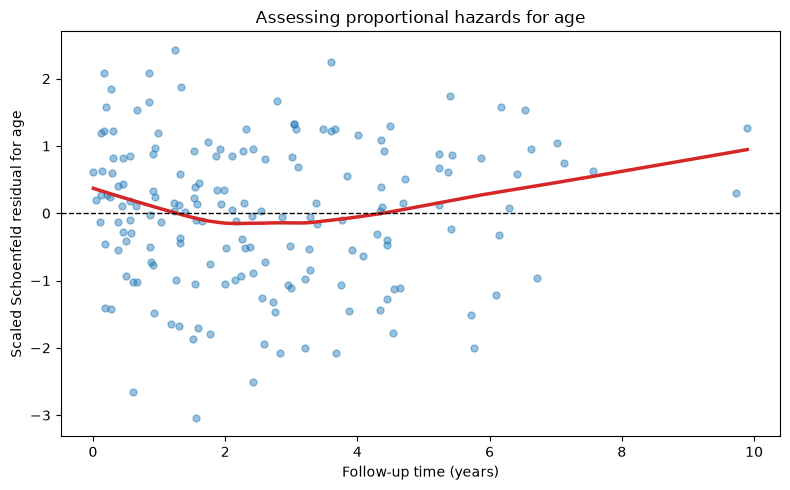

In [17]:
# 02-11 Inspects age proportional-hazards pattern

age_residuals = stratified_clinical_cox_model.compute_residuals(
    stratified_cox_data,
    kind="scaled_schoenfeld",
)

age_plot_data = pd.DataFrame(
    {
        "follow_up_years": (
            stratified_cox_data.loc[
                age_residuals.index,
                "overall_survival_days",
            ] / 365.25
        ),
        "age_residual": age_residuals["age_per_10_years"],
    }
)

plt.figure(figsize=(8, 5))

sns.regplot(
    data=age_plot_data,
    x="follow_up_years",
    y="age_residual",
    lowess=True,
    scatter_kws={"alpha": 0.45, "s": 25},
    line_kws={"color": "#D62728", "linewidth": 2.5},
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Follow-up time (years)")
plt.ylabel("Scaled Schoenfeld residual for age")
plt.title("Assessing proportional hazards for age")
plt.tight_layout()

FIGURES_DIR = PROJECT_DIR / "results" / "figures"
age_ph_figure_file = FIGURES_DIR / "figure_03_age_proportional_hazards_check.png"

In [18]:
print(age_ph_figure_file)
print(age_ph_figure_file.exists())

/Users/drsweetyramnani/Documents/Research_Projects/Cancer_genomics-tcga_kirc_survival_analysis/results/figures/figure_03_age_proportional_hazards_check.png
False


### Check proportional hazards across time transformations

**Purpose:** Determine whether the possible age violation is consistent across
multiple Schoenfeld-residual tests.

In [20]:
# 02-12  Checks proportional hazards across time transformations

time_transforms = ["rank", "km", "identity", "log"]
ph_test_tables = []

for time_transform in time_transforms:
    test_result = proportional_hazard_test(
        stratified_clinical_cox_model,
        stratified_cox_data,
        time_transform=time_transform,
    )

    test_table = test_result.summary[["test_statistic", "p"]].copy()
    test_table["time_transform"] = time_transform
    test_table["covariate"] = test_table.index

    ph_test_tables.append(test_table.reset_index(drop=True))

ph_robustness_results = pd.concat(
    ph_test_tables,
    ignore_index=True,
)

ph_robustness_results = (
    ph_robustness_results
    .rename(columns={"p": "p_value"})
    [["time_transform", "covariate", "test_statistic", "p_value"]]
    .round(4)
)

display(ph_robustness_results)

,time_transform,covariate,test_statistic,p_value
0,rank,age_per_10_years,5.6375,0.0176
1,rank,high_grade,2.7460,0.0975
2,rank,male,0.7013,0.4023
3,km,age_per_10_years,0.0078,0.9296
4,km,high_grade,0.2601,0.6101
5,km,male,0.0542,0.8159
6,identity,age_per_10_years,0.2196,0.6394
7,identity,high_grade,0.2575,0.6119
8,identity,male,0.0124,0.9115
9,log,age_per_10_years,1.4017,0.2364


### Save primary clinical Cox-model results

**Purpose:** Saves the stage-stratified clinical Cox-model estimates.

**Primary model:** Stratified by pathological stage; adjusted for age, sex, and grade group.

In [22]:
# 02-13 Saves primary clinical Cox-model results

RESULTS_TABLES_DIR = PROJECT_DIR / "results" / "tables"
RESULTS_TABLES_DIR.mkdir(parents=True, exist_ok=True)

clinical_cox_results_file = (
    RESULTS_TABLES_DIR / "table_01_stratified_clinical_cox_results.csv"
)

stratified_clinical_results.to_csv(
    clinical_cox_results_file,
    index_label="predictor",
)

print(f"Results table saved as: {clinical_cox_results_file.name}")

display(stratified_clinical_results)

Results table saved as: table_01_stratified_clinical_cox_results.csv


,hazard_ratio,lower_95_CI,upper_95_CI,p_value
covariate,,,,
age_per_10_years,1.360,1.176,1.572,0.000
male,0.991,0.721,1.361,0.953
high_grade,1.614,1.116,2.333,0.011


### Plot clinical Cox-model hazard ratios

**Purpose:** Create a forest plot of adjusted hazard ratios from the primary
stage-stratified clinical Cox model.

**Interpretation:** The vertical line at hazard ratio = 1 indicates no association.

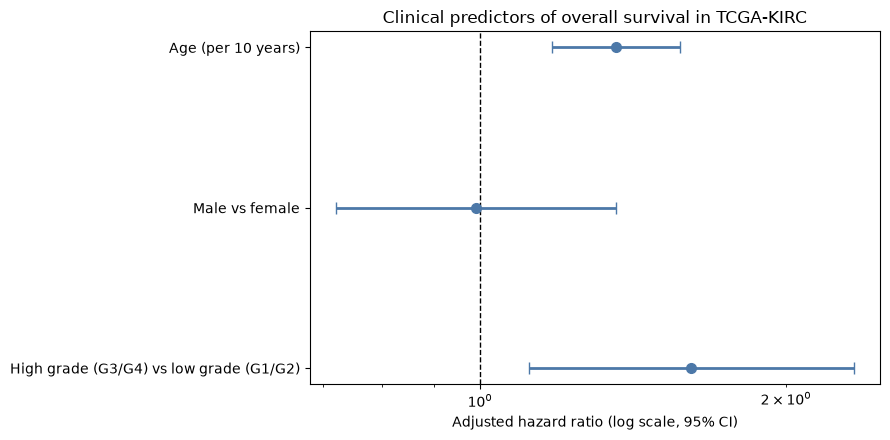

Figure saved as: figure_04_clinical_cox_forest_plot.png


In [23]:
# 02-14 Plots clinical Cox-model hazard ratios

forest_data = pd.read_csv(clinical_cox_results_file)

predictor_labels = {
    "age_per_10_years": "Age (per 10 years)",
    "male": "Male vs female",
    "high_grade": "High grade (G3/G4) vs low grade (G1/G2)",
}

forest_data["label"] = forest_data["predictor"].map(predictor_labels)

forest_data = forest_data.iloc[::-1].reset_index(drop=True)

plt.figure(figsize=(9, 4.5))

plt.errorbar(
    x=forest_data["hazard_ratio"],
    y=forest_data["label"],
    xerr=[
        forest_data["hazard_ratio"] - forest_data["lower_95_CI"],
        forest_data["upper_95_CI"] - forest_data["hazard_ratio"],
    ],
    fmt="o",
    color="#4C78A8",
    ecolor="#4C78A8",
    elinewidth=2,
    capsize=4,
    markersize=7,
)

plt.axvline(1, color="black", linestyle="--", linewidth=1)
plt.xscale("log")
plt.xlabel("Adjusted hazard ratio (log scale, 95% CI)")
plt.ylabel("")
plt.title("Clinical predictors of overall survival in TCGA-KIRC")
plt.tight_layout()

clinical_forest_figure = (
    FIGURES_DIR / "figure_04_clinical_cox_forest_plot.png"
)

plt.savefig(clinical_forest_figure, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved as: {clinical_forest_figure.name}")

### Save proportional-hazards sensitivity results

**Purpose:** the multi-transform Schoenfeld-residual checks used to assess
the age proportional-hazards finding is saved.

In [24]:
# 02-15 Saves proportional-hazards sensitivity results

ph_results_file = (
    RESULTS_TABLES_DIR / "table_02_proportional_hazards_sensitivity_checks.csv"
)

ph_robustness_results.to_csv(ph_results_file, index=False)

print(f"Results table saved as: {ph_results_file.name}")
display(ph_robustness_results)

Results table saved as: table_02_proportional_hazards_sensitivity_checks.csv


,time_transform,covariate,test_statistic,p_value
0,rank,age_per_10_years,5.6375,0.0176
1,rank,high_grade,2.7460,0.0975
2,rank,male,0.7013,0.4023
3,km,age_per_10_years,0.0078,0.9296
4,km,high_grade,0.2601,0.6101
5,km,male,0.0542,0.8159
6,identity,age_per_10_years,0.2196,0.6394
7,identity,high_grade,0.2575,0.6119
8,identity,male,0.0124,0.9115
9,log,age_per_10_years,1.4017,0.2364


In Stage 02, I have built the “clinical baseline” for the project.
Question: using only information doctors already have, how well can we describe survival differences?
I have used:
- Age
- Sex
- Cancer stage
- Tumor grade
- Survival time and whether the patient died or was still alive at last follow-up
and what was found:
- Older age was linked with worse overall survival.
  - About 35% higher estimated death hazard for every additional 10 years of age.
- High-grade tumors (G3/G4) were linked with worse survival than low-grade tumors (G1/G2).
- Stage III and especially Stage IV cancer were linked with worse survival than Stage I.
- Sex was not clearly associated with survival after accounting for the other variables.


Notes:
- It is found four patients with zero follow-up time and excluded them from survival modeling.
- Excluded 11 more patients with missing or unusable stage/grade information.
- Final clinical cohort was set : 522 patients, with 173 deaths.
- Grade G1 had zero deaths, which broke the first Cox model. Therefore I have combined G1 and G2 into “low grade” .
- Stage did not meet the Cox model’s proportional-hazards assumption, so I have used a stratified model. That lets each stage have its own survival pattern over time.
- Age had one borderline assumption-test result, but it was not consistent across several checks.

This clinical model is the benchmark. In the next stage, I will add gene-expression data and test whether immune/inflammation genes improve prediction beyond age, sex, stage, and grade.